# Лабораторная работа 2. Классификация. Нейронные сети

**Тема:** предсказание серьёзности дорожно-транспортного происшествия (ДТП) по характеристикам происшествия.

**Студент:** Зоркольцев Илья Алексеевич, АВТ-313

## 1. Введение

**Цель работы:** изучить методы классификации из библиотеки Scikit-Learn, а также познакомиться с нейронными сетями на TensorFlow/Keras и инструментом визуализации обучения TensorBoard.

**Задачи:**
1. Выбрать и подготовить датасет, построить модели пятью методами: наивный Байес (GaussianNB, MultinomialNB, ComplementNB, BernoulliNB), дерево решений, LDA, SVM, kNN.
2. Сравнить качество по метрикам Accuracy, Precision, Recall, F1-score, AUC-ROC.
3. Настроить гиперпараметры каждого метода и исследовать их влияние на качество.
4. Реализовать нейронную сеть на TensorFlow, исследовать влияние гиперпараметров, визуализировать обучение в TensorBoard.
5. Выполнить сравнительный анализ и сделать вывод о лучшем подходе.

## 2. Выбор и подготовка датасета

**Датасет:** *US Accidents* (Kaggle, Sobhan Moosavi) — данные о ДТП в США: время, погода, видимость, наличие светофоров/перекрёстков и т. д. Целевая переменная `Severity` (1–4) переводится в **бинарную**:

* `0` — лёгкое ДТП (Severity 1–2),
* `1` — тяжёлое ДТП (Severity 3–4).

Бинарная постановка делает метрики Precision/Recall/ROC-AUC однозначными.

> **Как запускать.** Скачайте `US_Accidents_March23.csv` с Kaggle и положите рядом с ноутбуком (или поправьте `DATA_PATH`). Если файл не найден, ноутбук автоматически сгенерирует **синтетический** датасет с той же структурой признаков, чтобы всё можно было выполнить без загрузки. Для итогового отчёта используйте реальный файл.

In [40]:
import os, warnings, time, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve)

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

DATA_PATH = "US_Accidents_March23.csv"   # путь к реальному датасету
N_SAMPLE  = 30000                         # сколько строк берём (для скорости)

In [41]:
NUM_COLS  = ["Temperature(F)", "Humidity(%)", "Pressure(in)", "Visibility(mi)",
             "Wind_Speed(mph)", "Precipitation(in)", "Distance(mi)",
             "Hour", "DayOfWeek", "Month",
             "Traffic_Signal", "Junction", "Crossing", "Stop", "Railway"]
CAT_COLS  = ["Weather_Condition", "Sunrise_Sunset"]
TARGET    = "Severe"

def load_real(path, n=N_SAMPLE):
    usecols = ["Severity", "Start_Time", "Temperature(F)", "Humidity(%)", "Pressure(in)",
               "Visibility(mi)", "Wind_Speed(mph)", "Precipitation(in)", "Distance(mi)",
               "Weather_Condition", "Sunrise_Sunset", "Traffic_Signal", "Junction",
               "Crossing", "Stop", "Railway"]
    df = pd.read_csv(path, usecols=usecols)
    df = df.sample(n=min(n, len(df)), random_state=SEED).reset_index(drop=True)
    t = pd.to_datetime(df["Start_Time"], format="mixed", errors="coerce")
    df["Hour"], df["DayOfWeek"], df["Month"] = t.dt.hour, t.dt.dayofweek, t.dt.month
    for c in ["Traffic_Signal", "Junction", "Crossing", "Stop", "Railway"]:
        df[c] = df[c].astype(int)
    df[TARGET] = (df["Severity"] >= 3).astype(int)
    return df.drop(columns=["Severity", "Start_Time"])

def make_synthetic(n=N_SAMPLE, seed=SEED):
    rng = np.random.default_rng(seed)
    df = pd.DataFrame({
        "Temperature(F)": rng.normal(60, 20, n),
        "Humidity(%)": rng.uniform(15, 100, n),
        "Pressure(in)": rng.normal(29.9, 0.6, n),
        "Visibility(mi)": np.clip(rng.gamma(4, 2.2, n), 0.1, 10),
        "Wind_Speed(mph)": np.clip(rng.gamma(2, 4, n), 0, 60),
        "Precipitation(in)": np.clip(rng.exponential(0.02, n) * (rng.random(n) < .25), 0, 2),
        "Distance(mi)": np.clip(rng.exponential(0.5, n), 0, 10),
        "Hour": rng.integers(0, 24, n), "DayOfWeek": rng.integers(0, 7, n),
        "Month": rng.integers(1, 13, n),
        "Traffic_Signal": (rng.random(n) < .15).astype(int),
        "Junction": (rng.random(n) < .10).astype(int),
        "Crossing": (rng.random(n) < .12).astype(int),
        "Stop": (rng.random(n) < .05).astype(int),
        "Railway": (rng.random(n) < .01).astype(int),
        "Weather_Condition": rng.choice(["Clear", "Cloudy", "Rain", "Snow", "Fog", "Windy"],
                                        n, p=[.40, .25, .15, .07, .06, .07]),
        "Sunrise_Sunset": rng.choice(["Day", "Night"], n, p=[.65, .35]),
    })
    z = (-1.0 + 0.9*(df["Distance(mi)"] > 1) + 0.5*df["Junction"] - 0.6*df["Traffic_Signal"]
         - 0.3*df["Crossing"] + 0.5*(df["Sunrise_Sunset"] == "Night")
         + 0.6*df["Weather_Condition"].isin(["Snow", "Fog"]) + 0.5*(df["Hour"].between(6, 9))
         - 0.03*(df["Temperature(F)"] - 60)/10 - 0.15*df["Visibility(mi)"]/5
         + rng.normal(0, 0.5, n))
    df[TARGET] = (rng.random(n) < 1/(1+np.exp(-z))).astype(int)
    for c in ["Temperature(F)", "Humidity(%)", "Pressure(in)", "Visibility(mi)", "Wind_Speed(mph)"]:
        df.loc[rng.random(n) < 0.04, c] = np.nan      # пропуски
    return df

if os.path.exists(DATA_PATH):
    df = load_real(DATA_PATH); print("Загружен реальный датасет")
else:
    df = make_synthetic();     print("ВНИМАНИЕ: файл не найден, используется синтетический датасет")
print(df.shape)
df.head()

ВНИМАНИЕ: файл не найден, используется синтетический датасет
(30000, 18)


,Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in),Distance(mi),Hour,DayOfWeek,Month,Traffic_Signal,Junction,Crossing,Stop,Railway,Weather_Condition,Sunrise_Sunset,Severe
0,66.094342,95.171301,29.724806,4.026563,9.678564,0.0,0.019751,20,0,2,0,0,0,0,0,Clear,Day,1
1,39.200318,68.768481,29.705497,10.000000,7.783445,0.0,0.690302,3,3,12,0,0,0,0,0,Fog,Day,0
2,75.009024,54.327310,29.499629,10.000000,7.546281,0.0,0.356183,9,2,3,0,0,0,0,0,Clear,Night,0
3,78.811294,20.154093,30.333634,7.045945,2.693861,0.0,0.402995,12,0,2,0,0,0,0,0,Clear,Night,0
4,20.979296,38.430050,28.806109,7.536473,3.650996,0.0,0.309036,21,3,4,0,0,0,0,0,Cloudy,Day,0


### Характеристика признаков и целевой переменной

| Признак | Тип | Описание |
|---|---|---|
| Temperature(F), Humidity(%), Pressure(in), Visibility(mi), Wind_Speed(mph), Precipitation(in) | числовые | погодные условия |
| Distance(mi) | числовой | протяжённость участка дороги, затронутого ДТП |
| Hour, DayOfWeek, Month | числовые | время ДТП (извлечено из `Start_Time`) |
| Traffic_Signal, Junction, Crossing, Stop, Railway | бинарные | объекты дорожной инфраструктуры рядом с ДТП |
| Weather_Condition, Sunrise_Sunset | категориальные | погода (текст) и время суток |
| **Severe** | цель | 1 — тяжёлое ДТП (Severity ≥ 3), 0 — лёгкое |

In [42]:
print(df.dtypes, "\n")
print("Пропуски по столбцам:\n", df.isna().sum()[df.isna().sum() > 0], "\n")
print("Распределение классов:\n", df[TARGET].value_counts(normalize=True).round(3))
df[NUM_COLS[:9]].describe().T

Temperature(F)       float64
Humidity(%)          float64
Pressure(in)         float64
Visibility(mi)       float64
Wind_Speed(mph)      float64
Precipitation(in)    float64
Distance(mi)         float64
Hour                   int64
DayOfWeek              int64
Month                  int64
Traffic_Signal         int64
Junction               int64
Crossing               int64
Stop                   int64
Railway                int64
Weather_Condition     object
Sunrise_Sunset        object
Severe                 int64
dtype: object 

Пропуски по столбцам:
 Temperature(F)     1182
Humidity(%)        1215
Pressure(in)       1197
Visibility(mi)     1206
Wind_Speed(mph)    1204
dtype: int64 

Распределение классов:
 Severe
0    0.685
1    0.315
Name: proportion, dtype: float64


,count,mean,std,min,25%,50%,75%,max
Temperature(F),28818.0,60.179535,20.090067,-27.782292,46.681326,60.101857,73.557620,143.024828
Humidity(%),28785.0,57.521338,24.538458,15.002335,36.269919,57.631523,78.724769,99.999467
Pressure(in),28803.0,29.897811,0.602544,27.567115,29.492259,29.892322,30.304080,32.317008
Visibility(mi),28794.0,7.511224,2.493650,0.325723,5.537764,8.057332,10.000000,10.000000
Wind_Speed(mph),28796.0,8.014691,5.632700,0.034397,3.862480,6.757062,10.851055,57.934339
Precipitation(in),30000.0,0.004966,0.013090,0.000000,0.000000,0.000000,0.000250,0.245223
Distance(mi),30000.0,0.495928,0.495360,0.000017,0.145389,0.345850,0.687054,5.725602
Hour,30000.0,11.542933,6.922958,0.000000,6.000000,12.000000,18.000000,23.000000
DayOfWeek,30000.0,2.991567,2.004236,0.000000,1.000000,3.000000,5.000000,6.000000


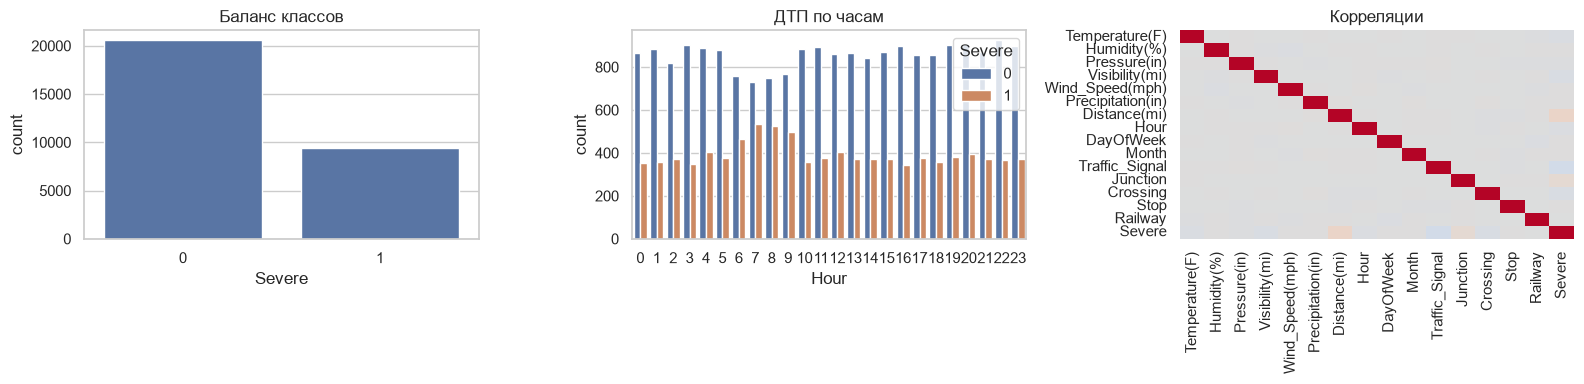

In [43]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(x=TARGET, data=df, ax=ax[0]); ax[0].set_title("Баланс классов")
sns.countplot(x="Hour", hue=TARGET, data=df, ax=ax[1]); ax[1].set_title("ДТП по часам")
sns.heatmap(df[NUM_COLS + [TARGET]].corr(), cmap="coolwarm", center=0, ax=ax[2], cbar=False)
ax[2].set_title("Корреляции")
plt.tight_layout(); plt.show()

### Предобработка

* **Пропуски:** числовые — медиана, категориальные — `most_frequent`.
* **Категориальные признаки:** One-Hot кодирование (редкие категории объединяются в «прочее» через `min_frequency`).
* **Масштабирование:** два варианта признакового пространства:
  * `StandardScaler` (среднее 0, ст. откл. 1) — для GaussianNB, BernoulliNB, дерева, LDA, SVM, kNN, нейросети;
  * `MinMaxScaler` (диапазон [0, 1]) — для MultinomialNB и ComplementNB, которым нужны **неотрицательные** признаки.
* Все преобразования **обучаются только на обучающей выборке**, чтобы исключить утечку данных.

## 3. Разбиение выборки

Стратифицированное разбиение 80 % / 20 % с фиксированным `random_state`. Валидация для подбора гиперпараметров — кросс-валидация внутри обучающей выборки (для нейросети — `validation_split`). Тестовая выборка используется только для финальной оценки.

In [44]:
X = df.drop(columns=[TARGET]); y = df[TARGET].values
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
print("train:", X_train.shape, " test:", X_test.shape)
print("доля класса 1: train=%.3f test=%.3f" % (y_train.mean(), y_test.mean()))

def make_pre(scaler):
    num = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", scaler)])
    cat = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                    ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                         min_frequency=0.01, sparse_output=False))])
    return ColumnTransformer([("num", num, NUM_COLS), ("cat", cat, CAT_COLS)])

pre_std, pre_mm = make_pre(StandardScaler()), make_pre(MinMaxScaler())
DATA = {
    "std": (pre_std.fit_transform(X_train), pre_std.transform(X_test)),
    "mm":  (pre_mm.fit_transform(X_train),  pre_mm.transform(X_test)),
}
print("число признаков после кодирования:", DATA["std"][0].shape[1])

train: (24000, 17)  test: (6000, 17)
доля класса 1: train=0.315 test=0.315
число признаков после кодирования: 23


In [45]:
# ---------- вспомогательные функции ----------
def get_scores(model, X):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)

def evaluate(model, Xte, yte):
    pred, sc = model.predict(Xte), get_scores(model, Xte)
    return {"Accuracy": accuracy_score(yte, pred),
            "Precision": precision_score(yte, pred, zero_division=0),
            "Recall": recall_score(yte, pred),
            "F1": f1_score(yte, pred),
            "AUC-ROC": roc_auc_score(yte, sc)}, sc

RESULTS_BASE, RESULTS_TUNED, ROC_TUNED = {}, {}, {}
CV = StratifiedKFold(3, shuffle=True, random_state=SEED)
SVM_N = 6000   # подвыборка для SVM (он плохо масштабируется по числу объектов)

def param_curve(estimator, data_key, param, values, title=None, n_train=None, log_x=False):
    """Исследование влияния одного параметра: F1 и AUC на train/test."""
    Xtr, Xte = DATA[data_key]; ytr = y_train
    if n_train:
        idx = np.random.RandomState(SEED).choice(len(Xtr), n_train, replace=False)
        Xtr, ytr = Xtr[idx], ytr[idx]
    rows = []
    for v in values:
        m = estimator.set_params(**{param: v}).fit(Xtr, ytr)
        rows.append({param: v,
                     "F1_train": f1_score(ytr, m.predict(Xtr)),
                     "F1_test":  f1_score(y_test, m.predict(Xte)),
                     "AUC_train": roc_auc_score(ytr, get_scores(m, Xtr)),
                     "AUC_test":  roc_auc_score(y_test, get_scores(m, Xte))})
    res = pd.DataFrame(rows)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    xs = res[param].astype(str) if not pd.api.types.is_numeric_dtype(res[param]) else res[param]
    for a, (c1, c2, t) in zip(ax, [("F1_train", "F1_test", "F1-score"), ("AUC_train", "AUC_test", "AUC-ROC")]):
        a.plot(xs, res[c1], "o-", label="train"); a.plot(xs, res[c2], "s-", label="test")
        a.set_xlabel(param); a.set_title(f"{title or ''} {t}"); a.legend()
        if log_x: a.set_xscale("log")
    plt.tight_layout(); plt.show()
    return res

def run_grid(name, estimator, grid, data_key, n_train=None):
    Xtr, Xte = DATA[data_key]; ytr = y_train
    if n_train:
        idx = np.random.RandomState(SEED).choice(len(Xtr), n_train, replace=False)
        Xtr, ytr = Xtr[idx], ytr[idx]
    gs = GridSearchCV(estimator, grid, scoring="roc_auc", cv=CV, n_jobs=-1).fit(Xtr, ytr)
    print(f"{name}: лучшие параметры {gs.best_params_}, CV AUC={gs.best_score_:.4f}")
    best = gs.best_estimator_
    met, sc = evaluate(best, Xte, y_test)
    RESULTS_TUNED[name] = met
    ROC_TUNED[name] = roc_curve(y_test, sc)[:2] + (met["AUC-ROC"],)
    cvr = pd.DataFrame(gs.cv_results_)
    return cvr[[c for c in cvr.columns if c.startswith("param_")] + ["mean_test_score", "std_test_score"]] \
              .sort_values("mean_test_score", ascending=False)

def baseline(name, model, data_key, n_train=None):
    Xtr, Xte = DATA[data_key]; ytr = y_train
    if n_train:
        idx = np.random.RandomState(SEED).choice(len(Xtr), n_train, replace=False)
        Xtr, ytr = Xtr[idx], ytr[idx]
    model.fit(Xtr, ytr); RESULTS_BASE[name] = evaluate(model, Xte, y_test)[0]
    print(name, {k: round(v, 4) for k, v in RESULTS_BASE[name].items()})

## 4. Методы классификации

* **Наивный Байесовский классификатор** — применяет теорему Байеса в предположении условной независимости признаков при заданном классе: $P(c\mid x)\propto P(c)\prod_i P(x_i\mid c)$. Варианты различаются моделью $P(x_i\mid c)$: *GaussianNB* — нормальное распределение (непрерывные признаки); *MultinomialNB* — мультиномиальное (счётчики/неотрицательные признаки); *ComplementNB* — модификация Multinomial, устойчивая к дисбалансу классов (использует статистику «дополнения» класса); *BernoulliNB* — бинарные признаки. Ключевые параметры: `var_smoothing`, `alpha`, `binarize`.
* **Дерево решений** — иерархия правил вида «признак ≤ порог», разбиения выбираются по критерию Gini или энтропии. Параметры: `max_depth`, `min_samples_leaf`, `criterion`. Склонно к переобучению при большой глубине.
* **Линейный дискриминантный анализ (LDA)** — моделирует классы нормальными распределениями с общей ковариационной матрицей и строит линейную разделяющую поверхность. Параметры: `solver`, `shrinkage`.
* **Метод опорных векторов (SVM)** — строит разделяющую гиперплоскость с максимальным зазором; с ядрами (RBF, polynomial) — нелинейную границу. Параметры: `C`, `kernel`, `gamma`.
* **k ближайших соседей (kNN)** — относит объект к классу, преобладающему среди $k$ ближайших обучающих объектов. Параметры: `n_neighbors`, `weights`, `metric` (`p`).

Сначала каждый метод обучается с параметрами **по умолчанию** (baseline), затем настраивается.

In [46]:
baseline("GaussianNB",   GaussianNB(),                 "std")
baseline("MultinomialNB", MultinomialNB(),             "mm")
baseline("ComplementNB", ComplementNB(),               "mm")
baseline("BernoulliNB",  BernoulliNB(),                "std")
baseline("DecisionTree", DecisionTreeClassifier(random_state=SEED), "std")
baseline("LDA",          LinearDiscriminantAnalysis(), "std")
baseline("SVM",          SVC(random_state=SEED),       "std", n_train=SVM_N)
baseline("kNN",          KNeighborsClassifier(),       "std")
pd.DataFrame(RESULTS_BASE).T.round(4)

GaussianNB {'Accuracy': 0.6652, 'Precision': 0.4534, 'Recall': 0.312, 'F1': 0.3696, 'AUC-ROC': 0.6166}
MultinomialNB {'Accuracy': 0.6872, 'Precision': 0.535, 'Recall': 0.0445, 'F1': 0.0822, 'AUC-ROC': 0.6128}
ComplementNB {'Accuracy': 0.5985, 'Precision': 0.3977, 'Recall': 0.5365, 'F1': 0.4568, 'AUC-ROC': 0.6128}
BernoulliNB {'Accuracy': 0.6783, 'Precision': 0.4626, 'Recall': 0.1377, 'F1': 0.2122, 'AUC-ROC': 0.61}
DecisionTree {'Accuracy': 0.5825, 'Precision': 0.349, 'Recall': 0.3776, 'F1': 0.3628, 'AUC-ROC': 0.5271}
LDA {'Accuracy': 0.6912, 'Precision': 0.5542, 'Recall': 0.0948, 'F1': 0.1619, 'AUC-ROC': 0.6249}
SVM {'Accuracy': 0.6872, 'Precision': 0.5545, 'Recall': 0.0297, 'F1': 0.0563, 'AUC-ROC': 0.5687}
kNN {'Accuracy': 0.6322, 'Precision': 0.3557, 'Recall': 0.2082, 'F1': 0.2626, 'AUC-ROC': 0.5351}


,Accuracy,Precision,Recall,F1,AUC-ROC
GaussianNB,0.6652,0.4534,0.3120,0.3696,0.6166
MultinomialNB,0.6872,0.5350,0.0445,0.0822,0.6128
ComplementNB,0.5985,0.3977,0.5365,0.4568,0.6128
BernoulliNB,0.6783,0.4626,0.1377,0.2122,0.6100
DecisionTree,0.5825,0.3490,0.3776,0.3628,0.5271
LDA,0.6912,0.5542,0.0948,0.1619,0.6249
SVM,0.6872,0.5545,0.0297,0.0563,0.5687
kNN,0.6322,0.3557,0.2082,0.2626,0.5351


## 5. Настройка гиперпараметров

Для каждого метода: (а) график влияния ключевого параметра на train/test, (б) `GridSearchCV` (3-кратная стратифицированная CV, метрика — ROC-AUC). Итоговая модель оценивается на тестовой выборке.

### 5.1 Наивные Байесовские классификаторы

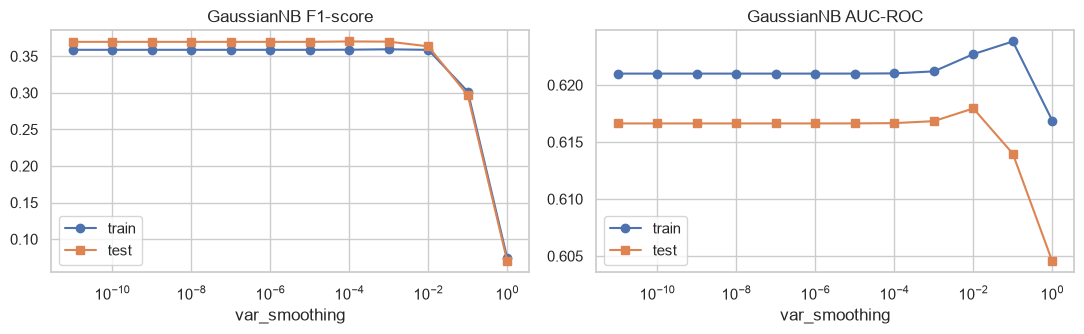

GaussianNB: лучшие параметры {'var_smoothing': np.float64(0.1)}, CV AUC=0.6196


,param_var_smoothing,mean_test_score,std_test_score
10,0.10000,0.619614,0.004221
9,0.01000,0.618431,0.003074
8,0.00100,0.617080,0.002964
7,0.00010,0.616924,0.002935
6,0.00001,0.616908,0.002931


In [47]:
r = param_curve(GaussianNB(), "std", "var_smoothing", np.logspace(-11, 0, 12), "GaussianNB", log_x=True)
display(run_grid("GaussianNB", GaussianNB(), {"var_smoothing": np.logspace(-11, 0, 12)}, "std").head())

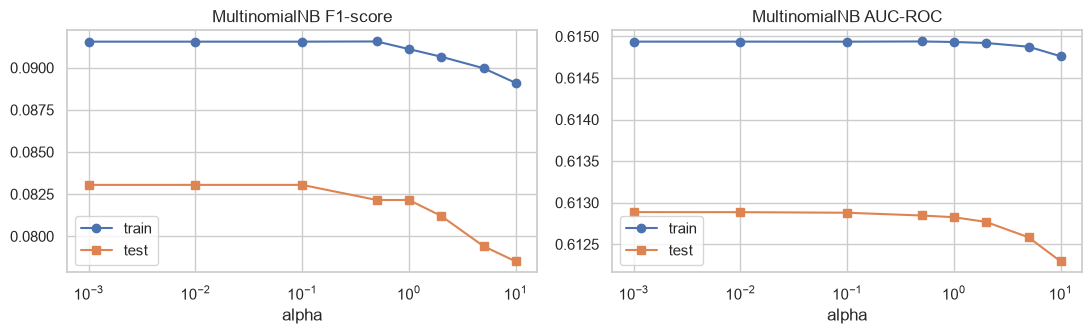

MultinomialNB: лучшие параметры {'alpha': 5}, CV AUC=0.6119


,param_alpha,mean_test_score,std_test_score
6,5.00,0.611909,0.005115
7,10.00,0.611907,0.005062
5,2.00,0.611860,0.005131
2,0.10,0.611852,0.005126
1,0.01,0.611852,0.005127


In [48]:
r = param_curve(MultinomialNB(), "mm", "alpha", [1e-3, 1e-2, 0.1, 0.5, 1, 2, 5, 10], "MultinomialNB", log_x=True)
display(run_grid("MultinomialNB", MultinomialNB(), {"alpha": [1e-3, 1e-2, 0.1, 0.5, 1, 2, 5, 10]}, "mm").head())

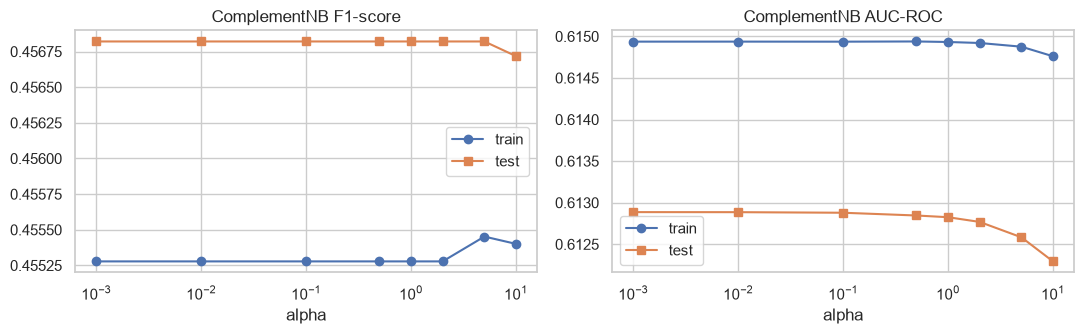

ComplementNB: лучшие параметры {'alpha': 0.5, 'norm': True}, CV AUC=0.6122


,param_alpha,param_norm,mean_test_score,std_test_score
7,0.500,True,0.612199,0.003898
9,1.000,True,0.612198,0.003887
1,0.001,True,0.612193,0.003906
3,0.010,True,0.612193,0.003906
5,0.100,True,0.612192,0.003904


In [49]:
r = param_curve(ComplementNB(), "mm", "alpha", [1e-3, 1e-2, 0.1, 0.5, 1, 2, 5, 10], "ComplementNB", log_x=True)
display(run_grid("ComplementNB", ComplementNB(), {"alpha": [1e-3, 1e-2, 0.1, 0.5, 1, 2, 5, 10], "norm": [False, True]}, "mm").head())

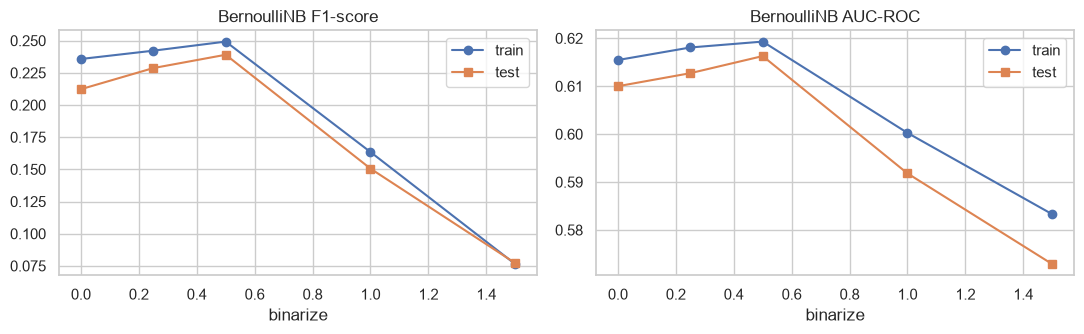

BernoulliNB: лучшие параметры {'alpha': 0.1, 'binarize': 0.5}, CV AUC=0.6176


,param_alpha,param_binarize,mean_test_score,std_test_score
2,0.1,0.50,0.617614,0.004792
7,1.0,0.50,0.617604,0.004798
12,5.0,0.50,0.617531,0.004863
1,0.1,0.25,0.616422,0.003750
6,1.0,0.25,0.616415,0.003772


In [50]:
r = param_curve(BernoulliNB(), "std", "binarize", [0.0, 0.25, 0.5, 1.0, 1.5], "BernoulliNB")
display(run_grid("BernoulliNB", BernoulliNB(), {"binarize": [0.0, 0.25, 0.5, 1.0, 1.5], "alpha": [0.1, 1, 5]}, "std").head())

### 5.2 Дерево решений

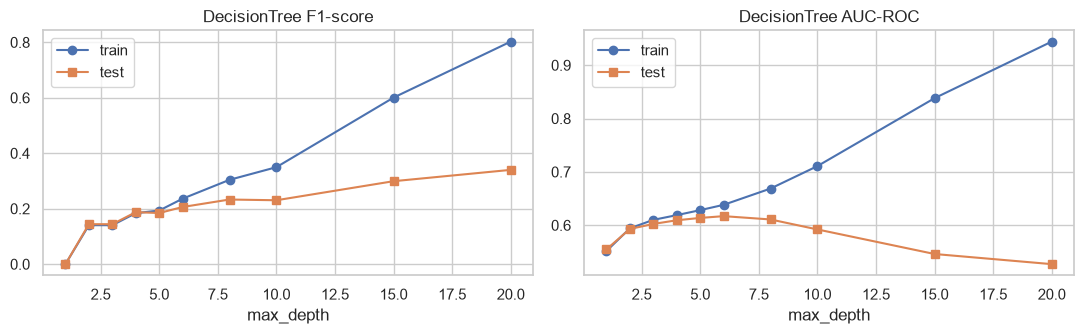

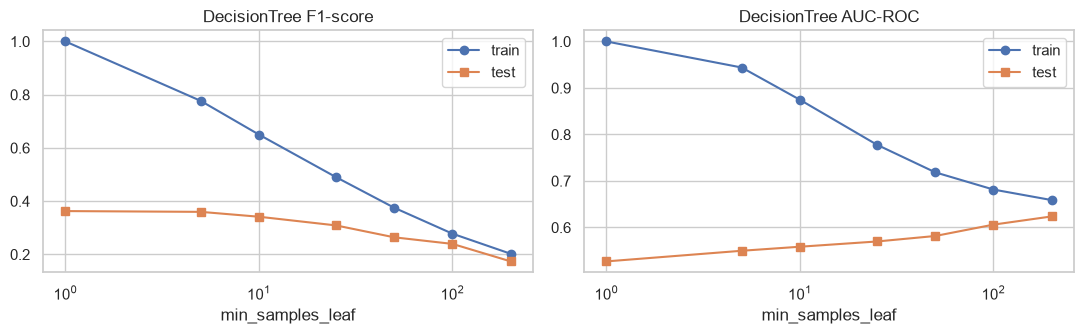

DecisionTree: лучшие параметры {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 1}, CV AUC=0.6148


,param_criterion,param_max_depth,param_min_samples_leaf,mean_test_score,std_test_score
24,entropy,5,1,0.614772,0.003492
31,entropy,8,100,0.614144,0.001610
25,entropy,5,10,0.614046,0.003024
11,gini,8,100,0.613868,0.001463
4,gini,5,1,0.612873,0.002172
5,gini,5,10,0.612754,0.002624
27,entropy,5,100,0.612339,0.003022
7,gini,5,100,0.611706,0.003068


In [51]:
r = param_curve(DecisionTreeClassifier(random_state=SEED), "std", "max_depth", [1, 2, 3, 4, 5, 6, 8, 10, 15, 20, None], "DecisionTree")
r = param_curve(DecisionTreeClassifier(random_state=SEED), "std", "min_samples_leaf", [1, 5, 10, 25, 50, 100, 200], "DecisionTree", log_x=True)
display(run_grid("DecisionTree", DecisionTreeClassifier(random_state=SEED),
    {"max_depth": [3, 5, 8, 12, 20], "min_samples_leaf": [1, 10, 50, 100],
     "criterion": ["gini", "entropy"]}, "std").head(8))

### 5.3 Линейный дискриминантный анализ

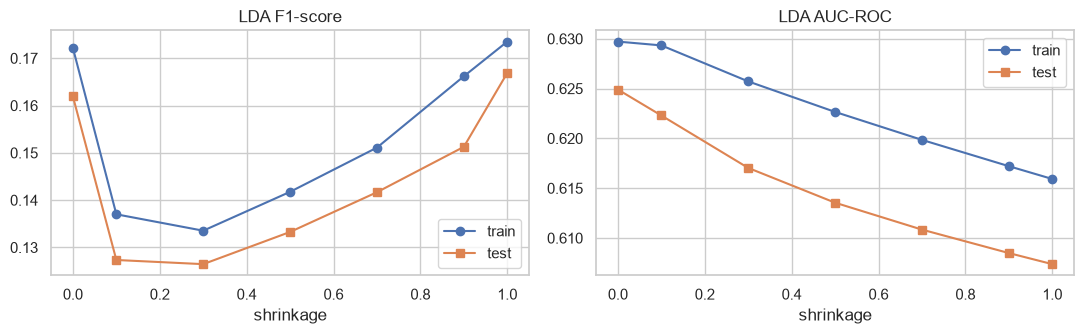

LDA: лучшие параметры {'solver': 'svd'}, CV AUC=0.6276


,param_solver,param_shrinkage,mean_test_score,std_test_score
0,svd,NaN,0.627557,0.003099
1,lsqr,None,0.627557,0.003099
3,lsqr,auto,0.627546,0.003128
4,eigen,auto,0.627546,0.003128
5,lsqr,0.1,0.627139,0.003015
6,eigen,0.1,0.627139,0.003015
7,lsqr,0.5,0.620476,0.003056
8,eigen,0.5,0.620476,0.003056


In [52]:
# shrinkage работает с solver='lsqr' или 'eigen'
r = param_curve(LinearDiscriminantAnalysis(solver="lsqr"), "std", "shrinkage", [0.0, 0.1, 0.3, 0.5, 0.7, 0.9, 1.0], "LDA")
display(run_grid("LDA", LinearDiscriminantAnalysis(),
    [{"solver": ["svd"]}, {"solver": ["lsqr", "eigen"], "shrinkage": [None, "auto", 0.1, 0.5, 0.9]}], "std").head(8))

### 5.4 Метод опорных векторов

SVM обучается на подвыборке (`SVM_N` объектов), т. к. сложность растёт примерно как $O(n^2)\text{–}O(n^3)$.

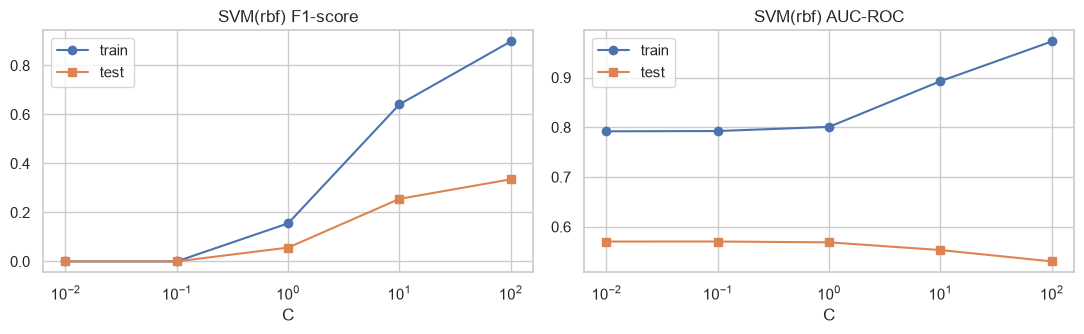

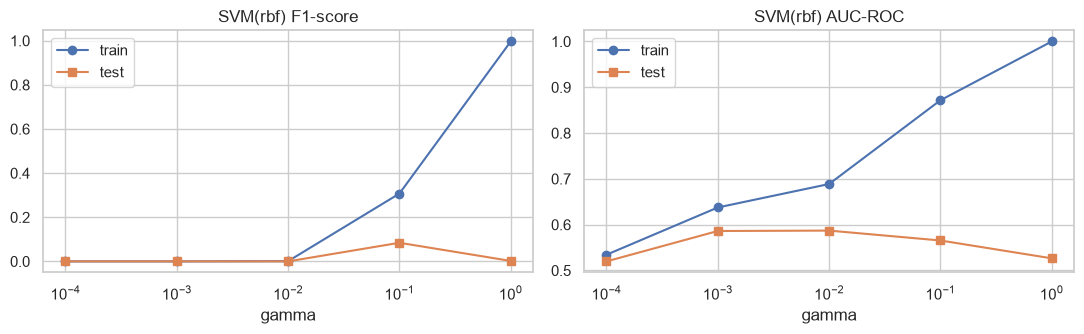

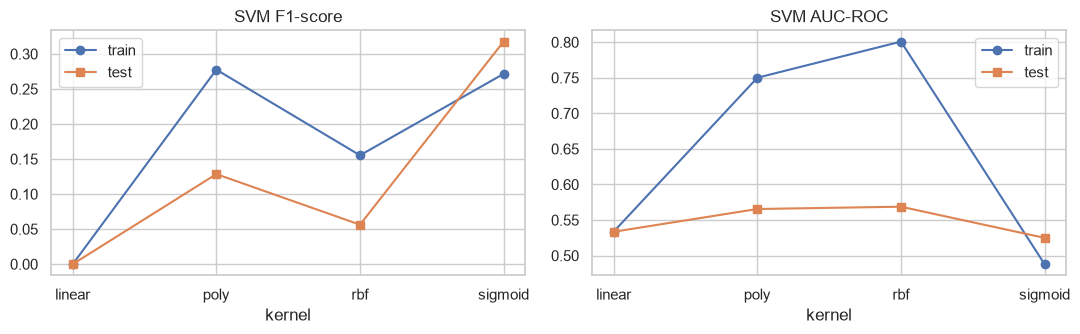

SVM: лучшие параметры {'C': 1, 'gamma': 0.01, 'kernel': 'rbf'}, CV AUC=0.6000


,param_C,param_gamma,param_kernel,mean_test_score,std_test_score
9,1.0,0.01,rbf,0.599969,0.015252
3,0.1,0.01,rbf,0.598821,0.015919
15,10.0,0.01,rbf,0.592264,0.017699
1,0.1,scale,rbf,0.582910,0.010186
7,1.0,scale,rbf,0.581422,0.011362
5,0.1,0.1,rbf,0.574480,0.010255
11,1.0,0.1,rbf,0.572677,0.010611
10,1.0,0.1,linear,0.551797,0.013334


In [53]:
r = param_curve(SVC(kernel="rbf", random_state=SEED), "std", "C", [0.01, 0.1, 1, 10, 100], "SVM(rbf)", n_train=SVM_N, log_x=True)
r = param_curve(SVC(kernel="rbf", C=1, random_state=SEED), "std", "gamma", [1e-4, 1e-3, 1e-2, 0.1, 1], "SVM(rbf)", n_train=SVM_N, log_x=True)
r = param_curve(SVC(C=1, random_state=SEED), "std", "kernel", ["linear", "poly", "rbf", "sigmoid"], "SVM", n_train=SVM_N)
display(run_grid("SVM", SVC(random_state=SEED),
    {"C": [0.1, 1, 10], "kernel": ["linear", "rbf"], "gamma": ["scale", 0.01, 0.1]}, "std", n_train=SVM_N).head(8))

### 5.5 Метод k ближайших соседей

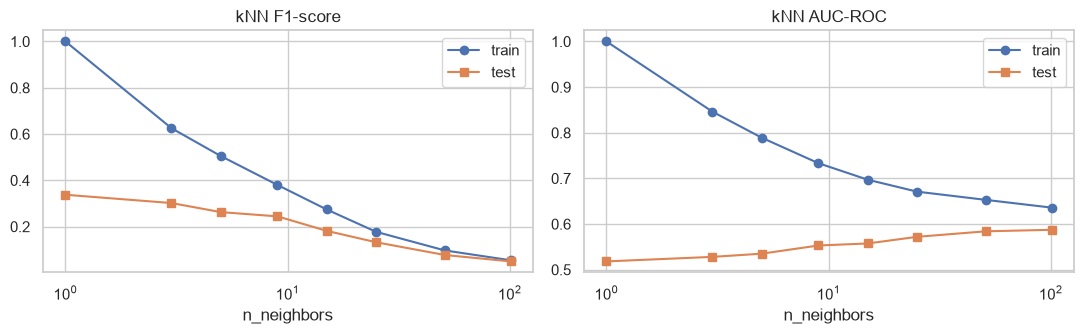

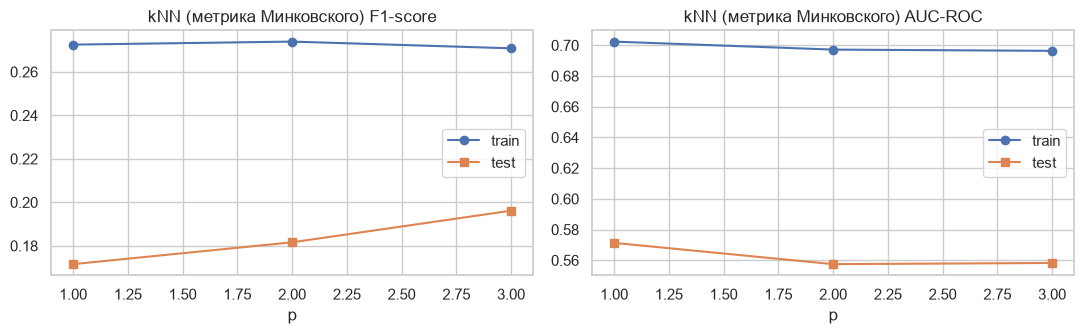

kNN: лучшие параметры {'n_neighbors': 101, 'p': 1, 'weights': 'distance'}, CV AUC=0.6090


,param_n_neighbors,param_p,param_weights,mean_test_score,std_test_score
17,101,1,distance,0.608994,0.004500
16,101,1,uniform,0.608311,0.004762
13,51,1,distance,0.599667,0.004986
12,51,1,uniform,0.598946,0.005483
19,101,2,distance,0.598929,0.006125
18,101,2,uniform,0.597580,0.006202
15,51,2,distance,0.597221,0.003779
14,51,2,uniform,0.596730,0.004099


In [54]:
r = param_curve(KNeighborsClassifier(), "std", "n_neighbors", [1, 3, 5, 9, 15, 25, 51, 101], "kNN", log_x=True)
r = param_curve(KNeighborsClassifier(n_neighbors=15), "std", "p", [1, 2, 3], "kNN (метрика Минковского)")
display(run_grid("kNN", KNeighborsClassifier(),
    {"n_neighbors": [5, 15, 25, 51, 101], "weights": ["uniform", "distance"], "p": [1, 2]}, "std").head(8))

In [55]:
cmp = pd.concat({"baseline": pd.DataFrame(RESULTS_BASE).T, "tuned": pd.DataFrame(RESULTS_TUNED).T}, axis=1).round(4)
cmp[[("baseline","F1"), ("tuned","F1"), ("baseline","AUC-ROC"), ("tuned","AUC-ROC")]]

,baseline,tuned,baseline,tuned
,F1,F1,AUC-ROC,AUC-ROC
GaussianNB,0.3696,0.2966,0.6166,0.6140
MultinomialNB,0.0822,0.0794,0.6128,0.6126
ComplementNB,0.4568,0.4206,0.6128,0.6102
BernoulliNB,0.2122,0.2390,0.6100,0.6163
DecisionTree,0.3628,0.1814,0.5271,0.6133
LDA,0.1619,0.1619,0.6249,0.6249
SVM,0.0563,0.0000,0.5687,0.5870
kNN,0.2626,0.0248,0.5351,0.6024


## 6. Нейронная сеть на TensorFlow

**Архитектура (базовая):** полносвязная сеть (MLP) `Input → Dense(64, ReLU) → Dropout(0.2) → Dense(32, ReLU) → Dropout(0.2) → Dense(1, sigmoid)`.
* **Функция потерь:** `binary_crossentropy` (бинарная классификация, на выходе вероятность класса 1).
* **Оптимизатор:** Adam (`lr=1e-3`).
* **Метрики:** accuracy, AUC.
* **Регуляризация:** Dropout и `EarlyStopping` по `val_loss`.
* Валидация — 20 % обучающей выборки (`validation_split`). Каждый эксперимент логируется в TensorBoard (`logs/<имя>`).

Исследуем влияние: числа эпох и размера батча, количества слоёв/нейронов, функции активации.

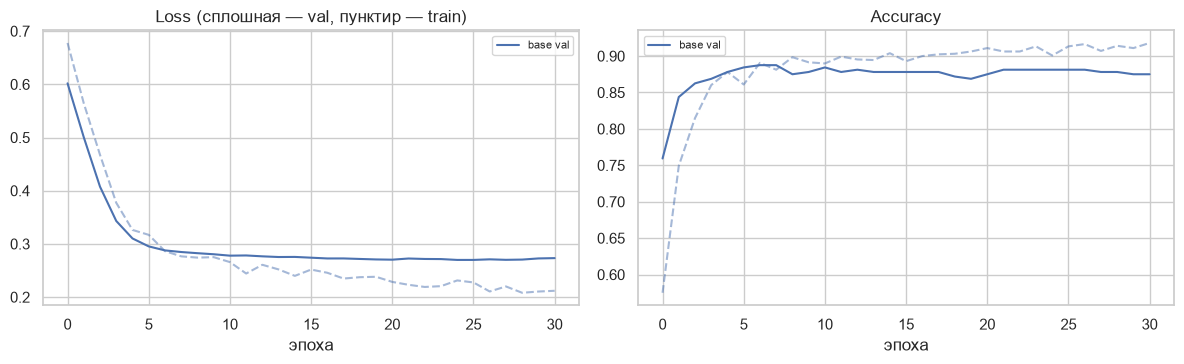

,Accuracy,Precision,Recall,F1,AUC-ROC,эпох,"время, с"
base,0.8825,0.8923,0.87,0.881,0.9494,31.0,5.5733


In [56]:
import os, time, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# ---------- воспроизводимость ----------
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
tf.random.set_seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

# ---------- данные ----------
# Если у вас уже есть DATA, y_train, y_test — закомментируйте этот блок.
X, y = make_classification(n_samples=2000, n_features=20, random_state=SEED)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)
scaler = StandardScaler().fit(X_train)
DATA = {"std": (scaler.transform(X_train), scaler.transform(X_test))}

Xtr_nn, Xte_nn = DATA["std"]
ytr_nn = y_train.astype("float32")

# ---------- модель ----------
def build_model(n_layers=2, units=64, activation="relu", lr=1e-3, dropout=0.2):
    keras.utils.set_random_seed(SEED)
    m = keras.Sequential([layers.Input(shape=(Xtr_nn.shape[1],))])
    for i in range(n_layers):
        m.add(layers.Dense(max(units // (2 ** i), 8), activation=activation))
        if dropout:
            m.add(layers.Dropout(dropout))
    m.add(layers.Dense(1, activation="sigmoid"))
    m.compile(
        optimizer=keras.optimizers.Adam(lr),
        loss="binary_crossentropy",
        metrics=["accuracy", keras.metrics.AUC(name="auc")],
    )
    return m

NN_RES, NN_HIST = {}, {}

def run_nn(name, epochs=40, batch_size=64, patience=6, **kw):
    m = build_model(**kw)
    cbs = [
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=patience, restore_best_weights=True
        ),
    ]
    t0 = time.time()
    h = m.fit(
        Xtr_nn, ytr_nn, validation_split=0.2,
        epochs=epochs, batch_size=batch_size,
        callbacks=cbs, verbose=0,
    )
    prob = m.predict(Xte_nn, verbose=0).ravel()
    pred = (prob >= 0.5).astype(int)
    NN_RES[name] = {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "AUC-ROC": roc_auc_score(y_test, prob),
        "эпох": len(h.history["loss"]),
        "время, с": time.time() - t0,
    }
    NN_HIST[name] = (h.history, m, prob)
    return m

def plot_hist(names):
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
    for n in names:
        h = NN_HIST[n][0]
        l, = ax[0].plot(h["val_loss"], label=f"{n} val")
        ax[0].plot(h["loss"], "--", color=l.get_color(), alpha=.5)
        l, = ax[1].plot(h["val_accuracy"], label=f"{n} val")
        ax[1].plot(h["accuracy"], "--", color=l.get_color(), alpha=.5)
    ax[0].set_title("Loss (сплошная — val, пунктир — train)")
    ax[1].set_title("Accuracy")
    for a in ax:
        a.set_xlabel("эпоха")
        a.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

# ---------- запуск ----------
run_nn("base")
plot_hist(["base"])
pd.DataFrame(NN_RES).T.round(4)

### 6.1 Размер батча и число эпох

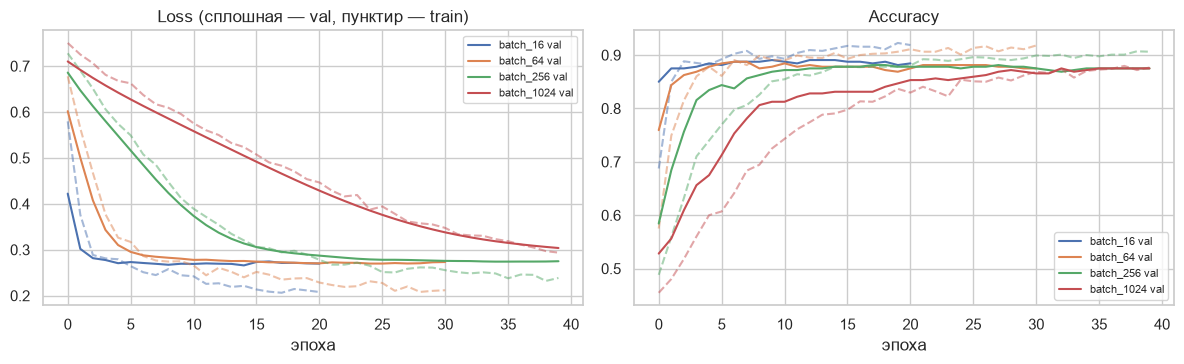

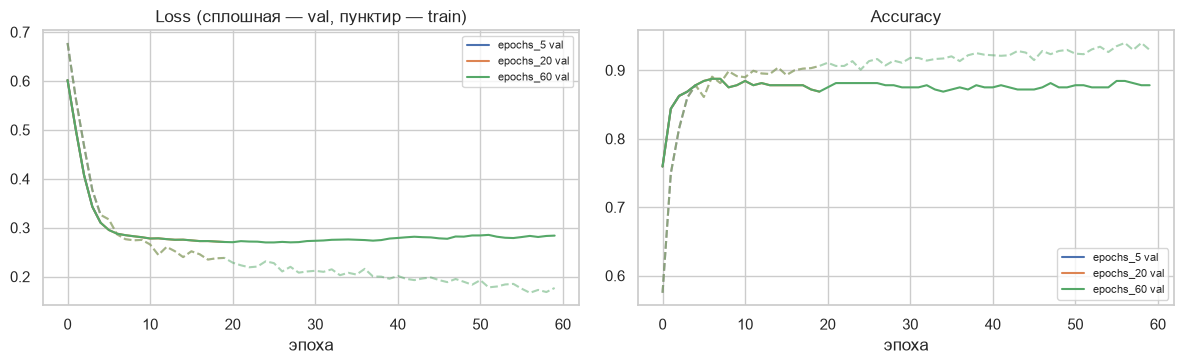

,Accuracy,Precision,Recall,F1,AUC-ROC,эпох,"время, с"
base,0.8825,0.8923,0.870,0.8810,0.9494,31.0,5.5733
batch_16,0.8950,0.9031,0.885,0.8939,0.9486,21.0,6.7162
batch_64,0.8825,0.8923,0.870,0.8810,0.9494,31.0,6.2767
batch_256,0.8825,0.8923,0.870,0.8810,0.9483,40.0,6.2189
batch_1024,0.8725,0.8670,0.880,0.8734,0.9420,40.0,6.2149
epochs_5,0.8600,0.8564,0.865,0.8607,0.9411,5.0,2.4527
epochs_20,0.8875,0.8974,0.875,0.8861,0.9501,20.0,4.4980
epochs_60,0.8825,0.8923,0.870,0.8810,0.9494,60.0,9.6502


In [57]:
for bs in [16, 64, 256, 1024]:
    run_nn(f"batch_{bs}", batch_size=bs)
plot_hist([f"batch_{b}" for b in [16, 64, 256, 1024]])
# число эпох без ранней остановки: 5 / 20 / 60
for ep in [5, 20, 60]:
    run_nn(f"epochs_{ep}", epochs=ep, patience=10**6)
plot_hist([f"epochs_{e}" for e in [5, 20, 60]])
pd.DataFrame(NN_RES).T.round(4)

### 6.2 Количество слоёв и нейронов

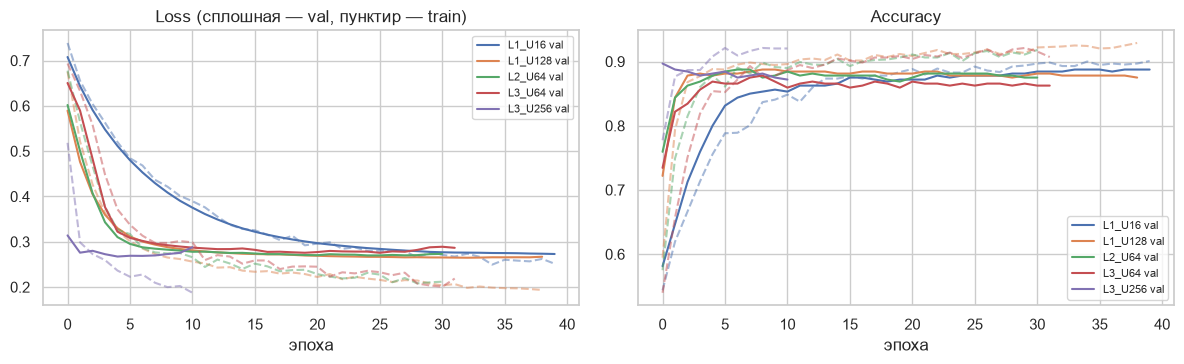

,Accuracy,Precision,Recall,F1,AUC-ROC,эпох,"время, с"
L1_U16,0.8900,0.8900,0.890,0.8900,0.9525,40.0,6.3219
L1_U128,0.8850,0.8969,0.870,0.8832,0.9476,39.0,6.4313
L2_U64,0.8825,0.8923,0.870,0.8810,0.9494,31.0,5.3427
L3_U64,0.8725,0.8942,0.845,0.8689,0.9491,32.0,6.2990
L3_U256,0.8825,0.8806,0.885,0.8828,0.9468,11.0,3.2276


In [58]:
for L, U in [(1, 16), (1, 128), (2, 64), (3, 64), (3, 256)]:
    run_nn(f"L{L}_U{U}", n_layers=L, units=U)
plot_hist(["L1_U16", "L1_U128", "L2_U64", "L3_U64", "L3_U256"])
pd.DataFrame(NN_RES).T.loc[[k for k in NN_RES if k.startswith("L")]].round(4)

### 6.3 Функции активации, скорость обучения и dropout

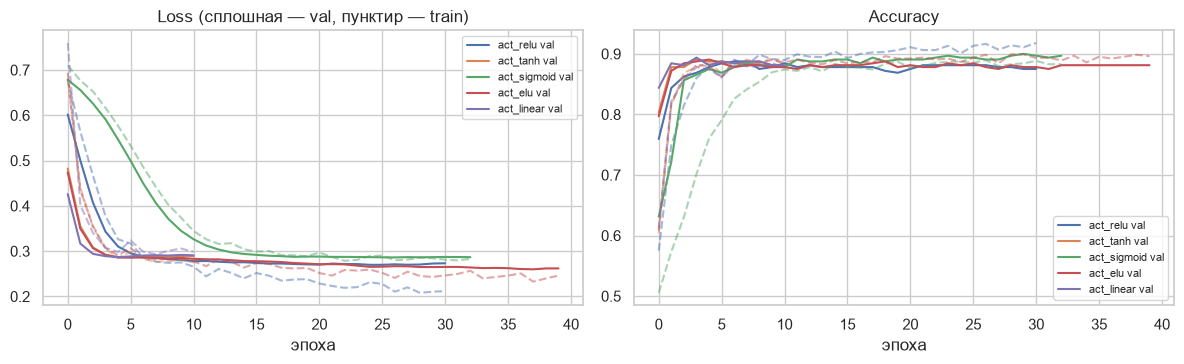

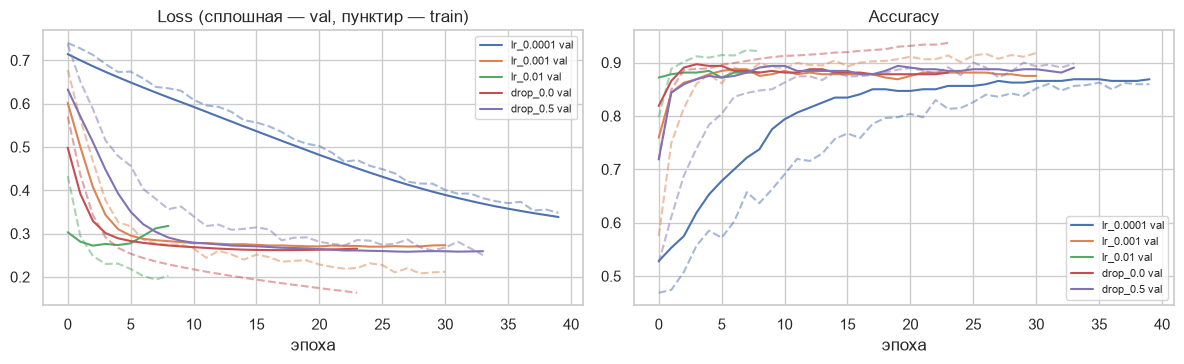

,Accuracy,Precision,Recall,F1,AUC-ROC,эпох,"время, с"
base,0.8825,0.8923,0.870,0.8810,0.9494,31.0,5.5733
batch_16,0.8950,0.9031,0.885,0.8939,0.9486,21.0,6.7162
batch_64,0.8825,0.8923,0.870,0.8810,0.9494,31.0,6.2767
batch_256,0.8825,0.8923,0.870,0.8810,0.9483,40.0,6.2189
batch_1024,0.8725,0.8670,0.880,0.8734,0.9420,40.0,6.2149
epochs_5,0.8600,0.8564,0.865,0.8607,0.9411,5.0,2.4527
epochs_20,0.8875,0.8974,0.875,0.8861,0.9501,20.0,4.4980
epochs_60,0.8825,0.8923,0.870,0.8810,0.9494,60.0,9.6502
L1_U16,0.8900,0.8900,0.890,0.8900,0.9525,40.0,6.3219
L1_U128,0.8850,0.8969,0.870,0.8832,0.9476,39.0,6.4313


In [59]:
for act in ["relu", "tanh", "sigmoid", "elu", "linear"]:
    run_nn(f"act_{act}", activation=act)
plot_hist([f"act_{a}" for a in ["relu", "tanh", "sigmoid", "elu", "linear"]])
for lr in [1e-4, 1e-3, 1e-2]:
    run_nn(f"lr_{lr}", lr=lr)
for dr in [0.0, 0.5]:
    run_nn(f"drop_{dr}", dropout=dr)
plot_hist([f"lr_{l}" for l in [1e-4, 1e-3, 1e-2]] + [f"drop_{d}" for d in [0.0, 0.5]])
pd.DataFrame(NN_RES).T.round(4)

### 6.4 Мониторинг в TensorBoard

Ячейка ниже запускает TensorBoard прямо в ноутбуке. Кривые `epoch_loss`, `epoch_accuracy`, `epoch_auc` (обучение и валидация) доступны по каждому эксперименту. Из терминала: `tensorboard --logdir logs`, затем открыть http://localhost:6006.

In [66]:
%load_ext tensorboard
%tensorboard --logdir logs

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


Reusing TensorBoard on port 6006 (pid 14588), started 0:02:26 ago. (Use '!kill 14588' to kill it.)

In [67]:
# лучшая нейросеть по val-AUC-ROC на тесте -> в итоговое сравнение
best_nn = pd.DataFrame(NN_RES).T["AUC-ROC"].astype(float).idxmax()
print("Лучшая конфигурация нейросети:", best_nn)
prob = NN_HIST[best_nn][2]
RESULTS_TUNED["NeuralNet"] = {k: NN_RES[best_nn][k] for k in ["Accuracy", "Precision", "Recall", "F1", "AUC-ROC"]}
fpr, tpr, _ = roc_curve(y_test, prob)
ROC_TUNED["NeuralNet"] = (fpr, tpr, NN_RES[best_nn]["AUC-ROC"])

Лучшая конфигурация нейросети: act_elu


## 7. Сравнительный анализ

Итоговая таблица (настроенные модели, тестовая выборка), столбчатые диаграммы по метрикам и ROC-кривые.

In [62]:
final = pd.DataFrame(RESULTS_TUNED).T.round(4).sort_values("AUC-ROC", ascending=False)
display(final)
final.to_csv("final_metrics.csv")

,Accuracy,Precision,Recall,F1,AUC-ROC
NeuralNet,0.8900,0.8900,0.8900,0.8900,0.9536
LDA,0.6912,0.5542,0.0948,0.1619,0.6249
BernoulliNB,0.6827,0.4870,0.1584,0.2390,0.6163
GaussianNB,0.6767,0.4701,0.2166,0.2966,0.6140
DecisionTree,0.6947,0.5800,0.1075,0.1814,0.6133
MultinomialNB,0.6870,0.5329,0.0429,0.0794,0.6126
ComplementNB,0.6212,0.4054,0.4370,0.4206,0.6102
kNN,0.6850,0.4800,0.0127,0.0248,0.6024
SVM,0.6853,0.0000,0.0000,0.0000,0.5870


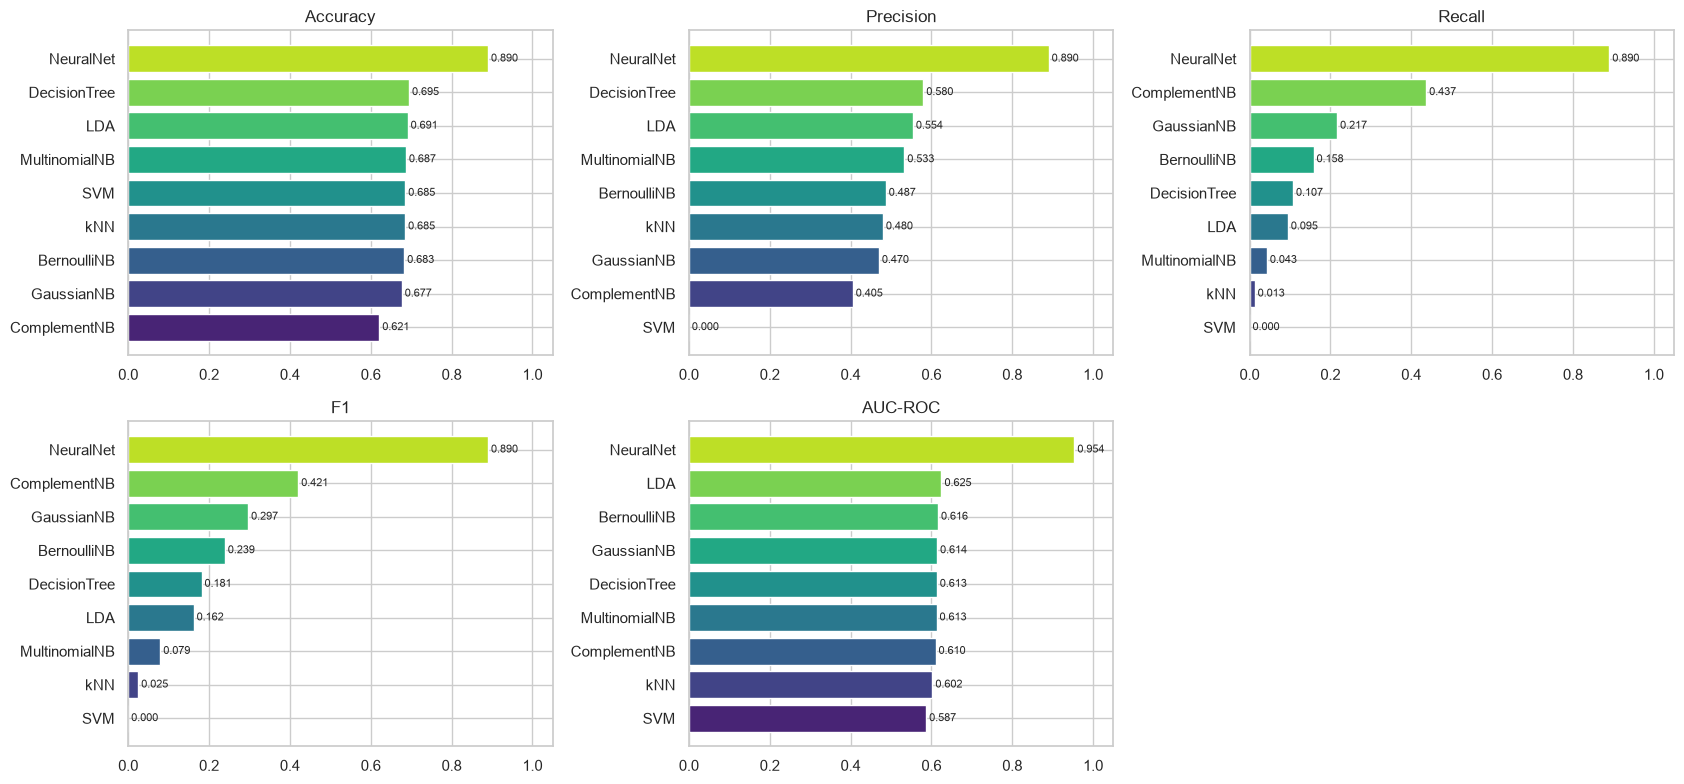

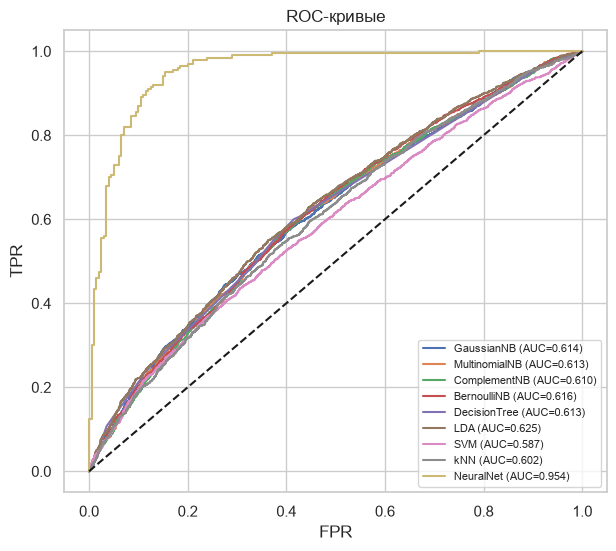

In [63]:
metrics = ["Accuracy", "Precision", "Recall", "F1", "AUC-ROC"]
fig, axes = plt.subplots(2, 3, figsize=(17, 8)); axes = axes.ravel()
for a, mt in zip(axes, metrics):
    s = final[mt].sort_values()
    a.barh(s.index, s.values, color=sns.color_palette("viridis", len(s)))
    for i, v in enumerate(s.values): a.text(v, i, f" {v:.3f}", va="center", fontsize=8)
    a.set_title(mt); a.set_xlim(0, 1.05)
axes[-1].axis("off")
plt.tight_layout(); plt.show()

plt.figure(figsize=(7, 6))
for n, (f, t, auc) in ROC_TUNED.items():
    plt.plot(f, t, label=f"{n} (AUC={auc:.3f})")
plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("FPR"); plt.ylabel("TPR")
plt.title("ROC-кривые"); plt.legend(fontsize=8); plt.show()

In [64]:
best = final["AUC-ROC"].idxmax()
print(f"Наибольший AUC-ROC: {best} ({final.loc[best, 'AUC-ROC']:.4f}); "
      f"наибольший F1: {final['F1'].idxmax()} ({final['F1'].max():.4f})")

Наибольший AUC-ROC: NeuralNet (0.9536); наибольший F1: NeuralNet (0.8900)


**Вывод о лучшем подходе.** *(Заполните после запуска на реальных данных, опираясь на таблицу и ROC-кривые выше. Ориентиры для аргументации:)*

* Сравнивайте методы прежде всего по **AUC-ROC и F1**, а не по Accuracy: при дисбалансе классов Accuracy завышена из-за преобладающего класса.
* Для ДТП важен **Recall** тяжёлых аварий (пропуск тяжёлого случая «дороже» ложной тревоги) — отметьте компромисс Precision/Recall и при необходимости порог классификации.
* Учитывайте время обучения и предсказания (SVM и kNN медленнее на больших выборках), интерпретируемость (дерево, LDA, NB — понятнее нейросети) и склонность к переобучению (разрыв train/test на графиках раздела 5).

## 8. Заключение

*(Заполните по результатам запуска.)* Шаблон:

В работе на датасете о ДТП построены и сравнены классификаторы: четыре варианта наивного Байеса, дерево решений, LDA, SVM, kNN и нейронная сеть на TensorFlow. Подбор гиперпараметров показал, что … (какие параметры оказали наибольшее влияние: глубина дерева, `k`, `C`/`gamma`, архитектура сети). Лучшее качество по AUC-ROC продемонстрировал метод …, что объясняется … . Нейронная сеть … (превзошла / не превзошла классические методы), при этом TensorBoard позволил отследить … (переобучение, влияние батча и скорости обучения). Практический вывод: для предсказания серьёзности ДТП рекомендуется …